# Solving the Schrodinger Equation
- The time independent Schrodinger equation is solved for a particle in a 2-dimensional infinite square well.
- Method: basis diagonalisation
- Elements of the Hamiltonian matrix are calculated using eigen-basis functions, through numerical differentiation and numerical integration.
- The Hamiltonian matrix is diagonalised to obtain the energies and wavefunctions (eigenvalues and eigenvectors) of the system.

In [2]:
"""
Edited by Apoorva Upadhyay.
Many thanks to Professor David Bowler who developed the original program.
Many thanks to Professor Jonathan Tennyson for editing the program.


"""
"""
- 2-dimensional Time Independent Schrodinger Equation, 1 particle in infinite square 2-dimensional well
- Basis diagonalisation method


- numerical partial differentiation of functions (or arrays) of many variables
- numerical integration over many variables
   

"""

from numpy import *
from matplotlib.pyplot import *
import numpy as np
import decimal
from decimal import Decimal

import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams['figure.dpi']=300 # highres display

from mpl_toolkits.mplot3d import Axes3D # import 3d plotting tool
from matplotlib import cm

import os

import re

import pandas as pd

from mpl_toolkits.axes_grid1.inset_locator import inset_axes
plt.rcParams['text.usetex'] = True

import math
import statistics

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from matplotlib.ticker import AutoMinorLocator, MultipleLocator

#################################################################
from scipy.linalg import eigh_tridiagonal
import scipy
from scipy.integrate import cumtrapz
from scipy.integrate import quad
from scipy.integrate import simps
from scipy import integrate
import numpy.linalg as la

from matplotlib.animation import FuncAnimation
import matplotlib.animation as animation

from matplotlib.animation import PillowWriter
from matplotlib.animation import FFMpegFileWriter
from matplotlib.animation import FFMpegWriter
#################################################################

In [3]:
# define constants

hbar_actual = scipy.constants.hbar
m_e_actual = scipy.constants.electron_mass
q_e_actual = scipy.constants.elementary_charge

# working in atomic units 
hbar = 1.0
m_e = 1.0
q_e = 1.0

# discretise x axis
L_x = 5
#x_min = -L_x/2
#x_max = L_x/2
x_min = 0.0
x_max = L_x
delta_x = 0.05
N_x = int((x_max - x_min)/(delta_x)+1)
x = np.linspace(x_min,x_max,N_x)

# discretise y axis
L_y = 5
#y_min = -L_y/2
#y_max = L_y/2
y_min = 0.0
y_max = L_y
delta_y = 0.05
N_y = int((y_max - y_min)/(delta_y)+1)
y = np.linspace(y_min,y_max,N_y)

# 2d x-y grid

X, Y = np.meshgrid(x, y)


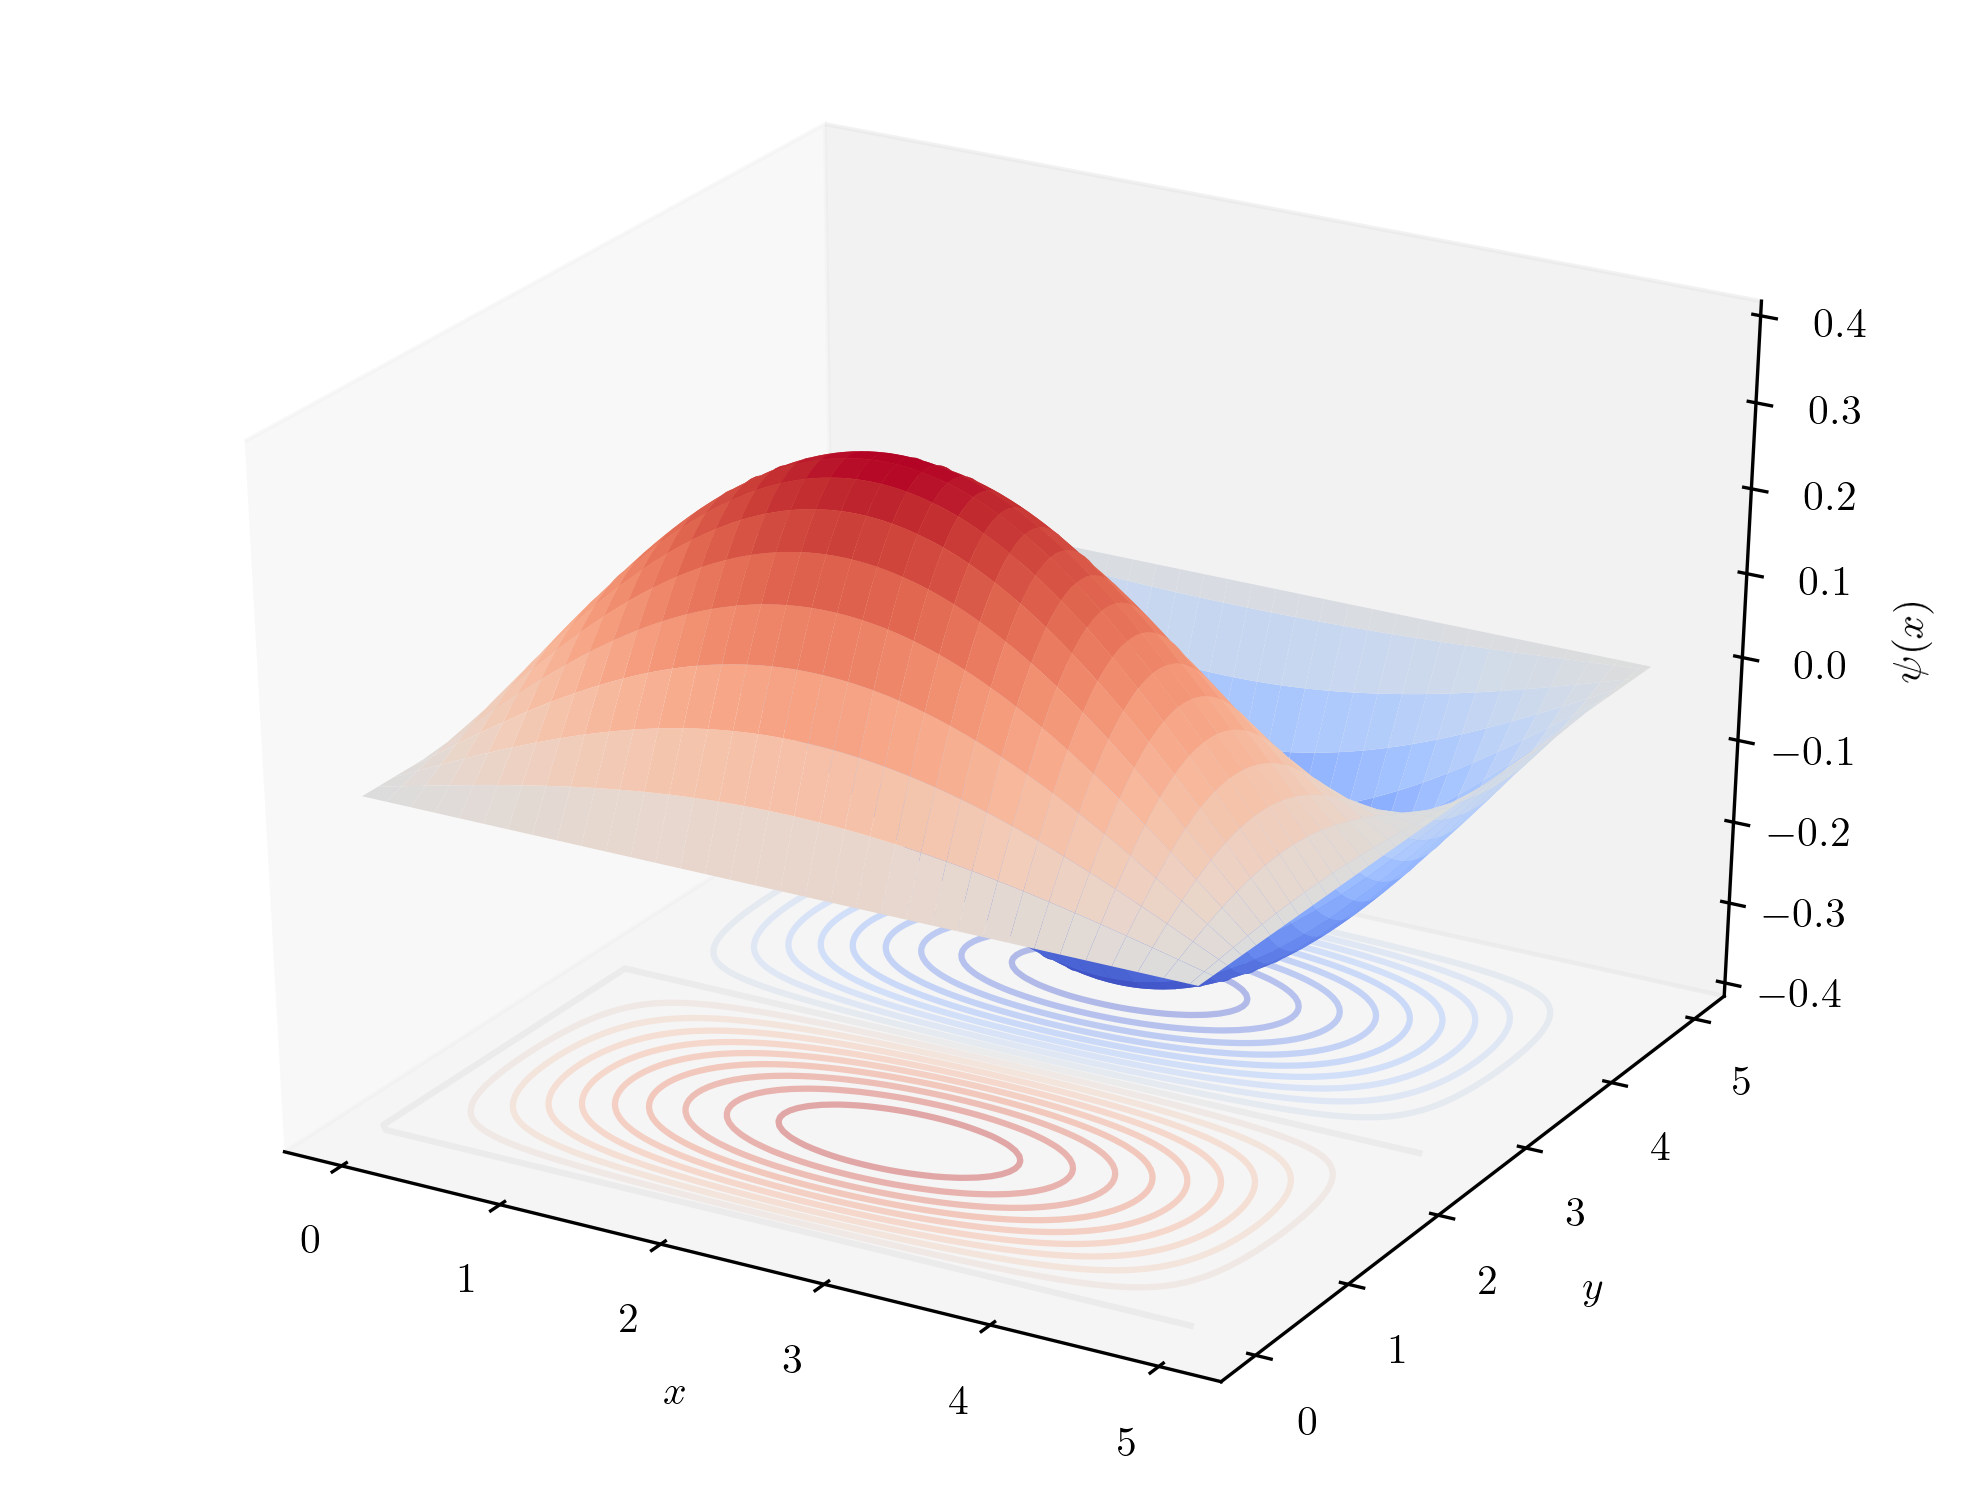

In [4]:
# define basis (W)Fs and do 3d surface plot

def InfiniteSquareWellWFsAnalytical_2d(data, n_x, n_y, L_x, L_y):
    x = data[0]
    y = data[1]
    
    #if x.any() and y.any() == 0.0:
        #BasisFunction = 0*x + 0*y
        #BasisFunction = np.dtype(object)
        
    #elif x.any() and y.any() != 0.0:
    norm1 = np.sqrt(2/L_x)
    norm2 = np.sqrt(2/L_y)
    #BasisFunction = norm1 * np.sin(((n_x * np.pi * x)/L_x) + ((n_x*np.pi)/2) ) * norm2 * np.sin(((n_y * np.pi * y)/L_y) + ((n_y*np.pi)/2) )
    BasisFunction = norm1 * np.sin(((n_x * np.pi * x)/L_x) ) * norm2 * np.sin(((n_y * np.pi * y)/L_y) )
        #BasisFunction = np.dtype(object)
    
    return BasisFunction


# generate 2d basis functions using m,n for n_x,n_y in double for loop
number_of_basis_functions = 10
basis_functions = []
#basis_functions_matrix = np.eye(number_of_basis_functions-1)

basis_functions_matrix = [[None for j in range(number_of_basis_functions)] for i in range(number_of_basis_functions)]

for i in range(0,len(basis_functions_matrix),1):
    for j in range(0,len(basis_functions_matrix[i]),1):
        #basis_functions_matrix[i][j] = np.zeros(np.random.randint(10)+1)
        basis_functions_matrix[i][j] = InfiniteSquareWellWFsAnalytical_2d(np.array([X, Y]), float(i)+1, float(j)+1, L_x, L_y)


for m in range(1,number_of_basis_functions,1):
    for n in range(1,number_of_basis_functions,1):
        basis_functions.append(InfiniteSquareWellWFsAnalytical_2d(np.array([X, Y]), n, m, L_x, L_y))
        #basis_functions_matrix[m,n] = InfiniteSquareWellWFsAnalytical_2d(np.array([X, Y]), n, m, L_x, L_y)


z = [[None for j in range(0,10,1)] for i in range(0,10,1)]

for i in range(0,len(z),1):
    for j in range(0,len(z[i]),1):
        z[i][j] = (int(i+1),int(j+1))
        
z_flat_list = [item for sublist in z for item in sublist]   

basis_functions_matrix_FlatList = [item for sublist in basis_functions_matrix for item in sublist]
################################################################

################################################################
# 3d surface plot to check basis functions

fig2 = plt.figure()
plotter3d = Axes3D(fig2) # create a 3d plotter attached to a new figure 
#plt.hold(True)

surf = plotter3d.plot_surface(X, Y,basis_functions_matrix_FlatList[1], cmap=cm.coolwarm,alpha=1.0)#rstride=1,cstride=1)#cmap='plasma'), cmap=cm.coolwarm
# THETA_smooth in radians
#plotter3d.plot_wireframe(X, Y, basis_functions[1], rstride=5, cstride=5, lw=0.5, colors='k',alpha=0.4)
#plotter3d.scatter(r2,theta,energy, c='r')

plotter3d.contour(X, Y, basis_functions_matrix_FlatList[1], 20,cmap=cm.coolwarm , linestyles="solid", offset=-1*np.amax(basis_functions_matrix_FlatList[1]),alpha=0.4)# cmap=cm.coolwarm
#plotter3d.contour(X, Y, Z, 10, lw=3, colors="k", linestyles="solid")
axes_object = plt.gca()

#axes_object.set_title('2D slice of the DMS along r1 = 2.3584 a.u. (x-component)', size=11, weight='bold')
axes_object.set_xlabel(r'$x$')
axes_object.set_ylabel(r'$y$')
axes_object.set_zlabel(r'$\psi(x)$')

# make the grid lines transparent
plotter3d.xaxis._axinfo["grid"]['color'] =  (1,1,1,0)
plotter3d.yaxis._axinfo["grid"]['color'] =  (1,1,1,0)
plotter3d.zaxis._axinfo["grid"]['color'] =  (1,1,1,0)
plt.show()


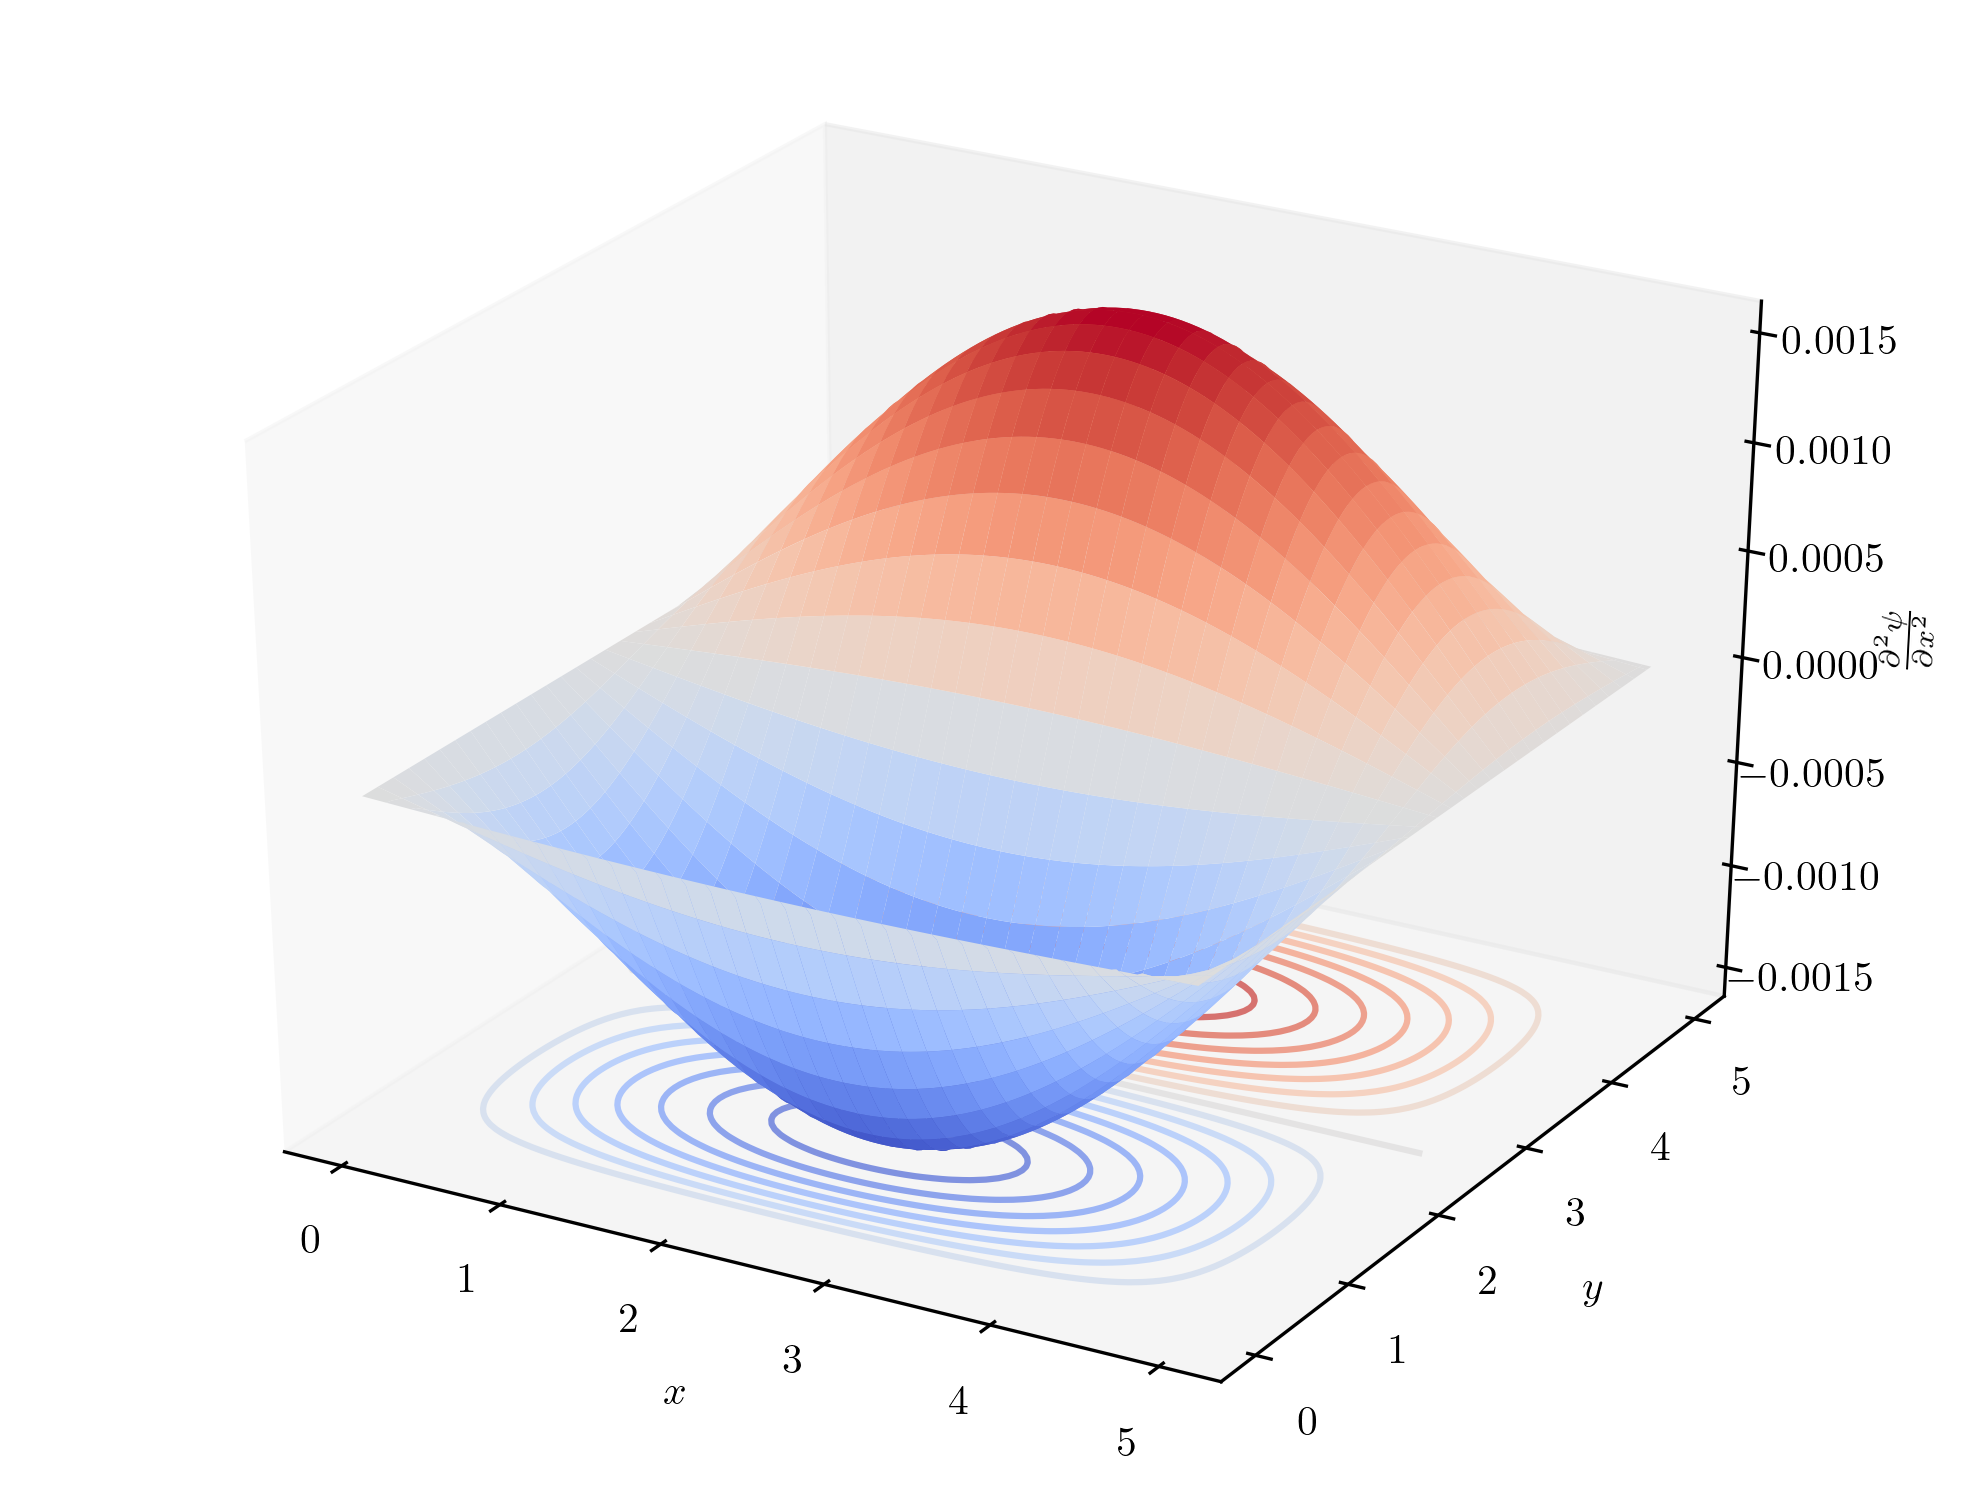

In [5]:
# numerical differentiation - 2 variables

dPsidx,dVPsidy = np.gradient(basis_functions_matrix_FlatList[1]) # 1st partial derivatives

d2Psidx2, d2Psidydx = np.gradient(dPsidx) # 2nd partial derivatives


fig3 = plt.figure()
plotter3d_2 = Axes3D(fig3) # create a 3d plotter attached to a new figure 
#plt.hold(True)

surf = plotter3d_2.plot_surface(X, Y,d2Psidx2, cmap=cm.coolwarm,alpha=1.0)#rstride=1,cstride=1)#cmap='plasma')
# THETA_smooth in radians

#plotter3d.scatter(r2,theta,energy, c='r')

# might be good to use offset = -max(d2Psidx2)
plotter3d_2.contour(X, Y, d2Psidx2, 20, cmap=cm.coolwarm, linestyles="solid", offset=-1*np.amax(d2Psidx2),alpha=0.7)
#plotter3d.contour(X, Y, Z, 10, lw=3, colors="k", linestyles="solid")
axes_object = plt.gca()

#axes_object.set_title('2D slice of the DMS along r1 = 2.3584 a.u. (x-component)', size=11, weight='bold')
axes_object.set_xlabel(r'$x$')
axes_object.set_ylabel(r'$y$')
axes_object.set_zlabel(r'$\frac{\partial^{2}\psi}{\partial x^{2}}$')

# make the grid lines transparent
plotter3d_2.xaxis._axinfo["grid"]['color'] =  (1,1,1,0)
plotter3d_2.yaxis._axinfo["grid"]['color'] =  (1,1,1,0)
plotter3d_2.zaxis._axinfo["grid"]['color'] =  (1,1,1,0)
plt.show()


In [8]:
# Build H matrix



# define infinite sqare well 2d potential
def potential(data):
    x = data[0]
    y = data[1]
    return 0*x + 0*y


# numerical differentiation 2D (of basis functions), using np.gradient
def NumericalDifferentiation_2D(array_data_basis):
    dBasisdx = np.gradient(array_data_basis,x, axis=1, edge_order=2) # 1st partial derivatives, edge_order deals with derivatives at boundary of domain
    d2Basisdx2 = np.gradient(dBasisdx,x, axis=1, edge_order=2) # 2nd partial derivatives
    
    dBasisdy = np.gradient(array_data_basis,y, axis=0, edge_order=2) # 1st partial derivatives, edge_order deals with derivatives at boundary of domain
    d2Basisdy2 = np.gradient(dBasisdy,y, axis=0, edge_order=2) # 2nd partial derivatives

    return d2Basisdx2,d2Basisdy2




# 2d potential acting on basis
def PotentialActingOnBasis(V,phi):
    for i in range(0,np.shape(V)[0],1):
        for j in range(0,np.shape(V)[1],1):
            V_on_phi = V[i,j] * phi[i,j]
    return V_on_phi

In [10]:
H_matrix = np.eye(number_of_basis_functions-1, dtype=np.float64)


for m in range(0,number_of_basis_functions-1,1):
    for n in range(0, number_of_basis_functions-1,1):
        
        #H_on_phiM = -0.5 * NumericalDifferentiation_2D(basis_functions[m])[0] + (-0.5 * NumericalDifferentiation_2D(basis_functions[m])[1]) + PotentialActingOnBasis(potential(np.array([X,Y])), basis_functions[m])
        #H_on_phiM = -0.5 * np.sum([NumericalDifferentiation_2D(basis_functions[m])[0], NumericalDifferentiation_2D(basis_functions[m])[1], PotentialActingOnBasis(potential(np.array([X,Y])), basis_functions[m])], axis=0)
        # work work? - H_on_phiM = -0.5 * NumericalDifferentiation_2D(InfiniteSquareWellWFsAnalytical_2d(np.array([X, Y]), n, m, L_x, L_y))[0] + (-0.5 * NumericalDifferentiation_2D(InfiniteSquareWellWFsAnalytical_2d(np.array([X, Y]), n, m, L_x, L_y))[1]) + PotentialActingOnBasis(potential(np.array([X,Y])), InfiniteSquareWellWFsAnalytical_2d(np.array([X, Y]), n, m, L_x, L_y)[m])
        H_on_phiM = -0.5 * NumericalDifferentiation_2D(basis_functions_matrix_FlatList[m])[0] + (-0.5 * NumericalDifferentiation_2D(basis_functions_matrix_FlatList[m])[1]) + PotentialActingOnBasis(potential(np.array([X,Y])), basis_functions_matrix_FlatList[m])
        
        phiN_on_H_on_phiM = basis_functions_matrix_FlatList[n] * H_on_phiM
        
        # integrate for matrix element
        # phiN_on_H_on_phiM = integrand
        
        H_nm = simps(simps(phiN_on_H_on_phiM, y), x)
        #H_nm = simps(simps(phiN_on_H_on_phiM, x), y)
        
        #H_nm = integrate.nquad(functionIntegrand_Hmatrix(a,phiN_on_H_on_phiM),[[x_min,x_max],[y_min,y_max]])

        
        H_matrix[m,n] = H_nm



eigenvalues, eigenvectors = la.eigh(H_matrix)

L = 5
square_well_width_squared = L**2
two_m_e = 2.0
pi_squared = np.pi**2
hbar_squared = 1.0



E_analytical_list = []

for n in range (1,10,1):
    E_analytical = hbar_squared*n*n*pi_squared/(two_m_e*square_well_width_squared)
    E_analytical_list.append(E_analytical)
    
#E_analytical_0_0 = hbar_squared*n*n*pi_squared/(two_m_e*square_well_width_squared)
E_analytical_1_1 = (1**2 + 1**2)*hbar_squared*pi_squared/(two_m_e*square_well_width_squared)


In [11]:
# Energies of the system (eigenvalues)
eigenvalues

array([ 0.39465918,  0.98590028,  1.96881088,  3.33967009,  5.09327319,
        7.22298817,  9.72071438, 12.57703949, 15.78105819])

In [12]:
# Analytical ground state energy of the system
E_analytical_1_1

0.3947841760435743

## Conclusion
- Ground state energy predicted using methodology of this program = 0.39465918
- Analytically calculated ground state energy = 0.39478418